# 0. Start here: what DMRG is for

This notebook is for readers who know what a qubit (or spin-1/2) and a Hamiltonian are, but have never met tensor networks. It answers one question in plain terms, with small runnable examples: **how can a laptop find the ground state of a chain of 60 interacting spins, when writing that state down exactly would need more memory than exists on Earth?** The answer is the density-matrix renormalization group (DMRG), and the four numbered notebooks then build it step by step.

Background portals: [ground state](https://en.wikipedia.org/wiki/Ground_state), [quantum entanglement](https://en.wikipedia.org/wiki/Quantum_entanglement), [singular value decomposition](https://en.wikipedia.org/wiki/Singular_value_decomposition). A gentle written introduction is R. Orús, [arXiv:1306.2164](https://arxiv.org/abs/1306.2164).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse.linalg import eigsh

import dmrg

## The question

Our model is the **transverse-field Ising chain**, the "hydrogen atom" of quantum many-body physics:

$$H = -\sum_i X_iX_{i+1} - h\sum_i Z_i .$$

Each term $-X_iX_{i+1}$ rewards neighbouring spins for pointing the same way along $x$; the field $h$ instead pulls every spin along $z$. For small $h$ the spins line up (a ferromagnet), for large $h$ they all follow the field (a paramagnet), and at $h = 1$ the two tendencies are balanced: a [quantum phase transition](https://en.wikipedia.org/wiki/Quantum_phase_transition). We want the **ground state**, the state of lowest energy, because it is what the system settles into at zero temperature and it decides the phase.

## The wall

A state of $L$ spins is a list of $2^L$ complex amplitudes, one per configuration $|\!\uparrow\downarrow\uparrow\cdots\rangle$. The memory needed grows exponentially:

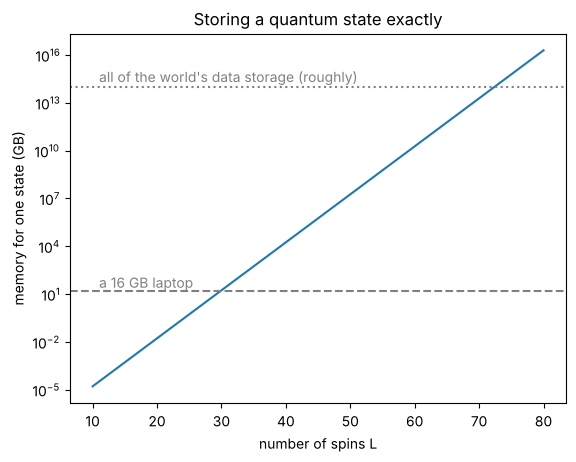

In [2]:
L = np.arange(10, 81)
gigabytes = 16 * 2.0**L / 1e9  # one complex number = 16 bytes

plt.semilogy(L, gigabytes)
plt.axhline(16, color="gray", ls="--")
plt.text(11, 25, "a 16 GB laptop", color="gray")
plt.axhline(1e14, color="gray", ls=":")
plt.text(11, 2e14, "all of the world's data storage (roughly)", color="gray")
plt.xlabel("number of spins L")
plt.ylabel("memory for one state (GB)")
plt.title("Storing a quantum state exactly");

Exact diagonalization stops near $L \approx 30$. Yet DMRG routinely handles hundreds of spins. It can, because ground states are **special**: they are far less entangled than a typical state.

## Ground states are barely entangled

Cut the chain into a left and a right half. Any state can be written as $|\psi\rangle = \sum_a S_a\, |a\rangle_{\rm left}|a\rangle_{\rm right}$ (the [Schmidt decomposition](https://en.wikipedia.org/wiki/Schmidt_decomposition), which is just an SVD of the amplitudes arranged as a matrix). The numbers $S_a$ say how entangled the halves are: one nonzero $S_a$ means no entanglement, many equal ones means a lot.

Compare a random state of 12 spins with the ground state of our chain:

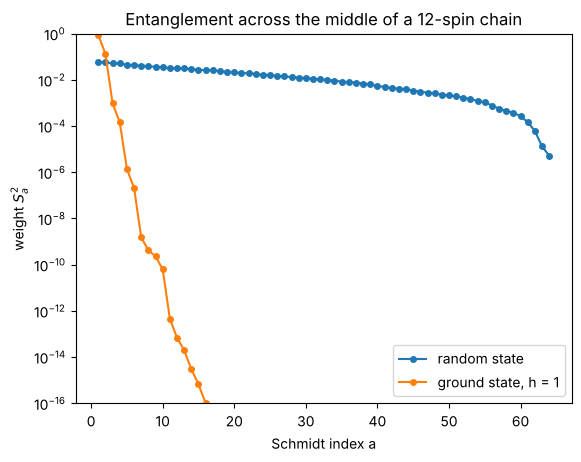

In [3]:
L = 12
rng = np.random.default_rng(0)
random_state = rng.normal(size=2**L) + 1j * rng.normal(size=2**L)
random_state /= np.linalg.norm(random_state)
ground_state = eigsh(dmrg.mpo_to_dense(dmrg.tfim_mpo(L, h=1.0)), k=1, which="SA")[1][:, 0]

for psi, label in [(random_state, "random state"), (ground_state, "ground state, h = 1")]:
    S = np.linalg.svd(psi.reshape(2 ** (L // 2), -1), compute_uv=False)  # rows: left half, columns: right half
    plt.semilogy(np.arange(1, len(S) + 1), S**2, "o-", ms=4, label=label)
plt.xlabel("Schmidt index a")
plt.ylabel("weight $S_a^2$")
plt.ylim(1e-16, 1)
plt.title("Entanglement across the middle of a 12-spin chain")
plt.legend();

For the random state all 64 weights are comparable: it is highly entangled. For the ground state the weights **fall off exponentially**, so keeping only the largest few, say $\chi = 8$ of them, loses almost nothing. This is the [area law](https://en.wikipedia.org/wiki/Area_law_(entanglement)) for ground states of local Hamiltonians (Hastings, [arXiv:0705.2024](https://arxiv.org/abs/0705.2024); review by Eisert, Cramer and Plenio, [arXiv:0808.3773](https://arxiv.org/abs/0808.3773)). It is the same idea as compressing a photograph by keeping its largest singular values.

## DMRG in one paragraph

Doing this compression at every cut writes the state as a **matrix product state** (MPS): a chain of small tensors, one per spin, each at most $\chi \times 2 \times \chi$ numbers. Memory now grows like $L\chi^2$ instead of $2^L$. DMRG ([White 1992](https://doi.org/10.1103/PhysRevLett.69.2863), which predates arXiv; modern review: Schollwöck, [arXiv:1008.3477](https://arxiv.org/abs/1008.3477)) finds the best MPS by **sweeping**: freeze all tensors except two neighbours, find the best values for those two (a small eigenvalue problem), compress back to $\chi$, move one site over, and repeat back and forth along the chain until the energy stops changing.

## Try it: 60 spins in seconds

$2^{60}$ amplitudes would take 18 million terabytes. DMRG with $\chi = 24$ needs a few megabytes. This chain happens to be exactly solvable (it maps to free fermions), so we can check the answer:

In [4]:
L = 60
results = {}
for h in [0.5, 1.0, 2.0]:
    t0 = time.time()
    results[h] = dmrg.dmrg(dmrg.tfim_mpo(L, h), chi_max=24, n_sweeps=3)
    exact = dmrg.tfim_open_energy(L, h)
    print(
        f"h = {h}: DMRG E = {results[h]['energy']:.10f}, exact E = {exact:.10f}, "
        f"error = {abs(results[h]['energy'] - exact):.0e}  ({time.time() - t0:.1f} s)"
    )

h = 0.5: DMRG E = -62.9419935507, exact E = -62.9419935507, error = 3e-13  (3.2 s)


h = 1.0: DMRG E = -76.0331561302, exact E = -76.0331561303, error = 1e-10  (9.9 s)


h = 2.0: DMRG E = -127.4937601121, exact E = -127.4937601121, error = 3e-13  (5.6 s)


The energies agree with the exact ones to $10^{-10}$ or better. Besides the energy, DMRG hands us the entanglement of every cut for free, and it tells the phases apart:

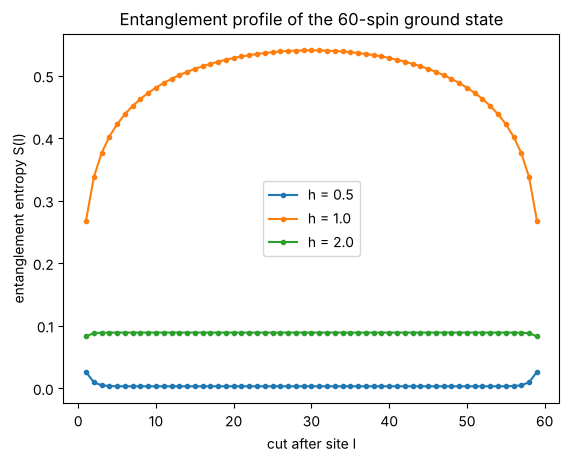

In [5]:
for h, res in results.items():
    plt.plot(np.arange(1, L), res["entropies"], "o-", ms=3, label=f"h = {h}")
plt.xlabel("cut after site l")
plt.ylabel("entanglement entropy S(l)")
plt.title(f"Entanglement profile of the {L}-spin ground state")
plt.legend();

Away from the transition ($h = 0.5$, $h = 2$) the entanglement saturates to a small constant: the area law in one dimension. At the critical point $h = 1$ it keeps growing, logarithmically: for an open chain $S(l) \approx \frac{c}{6}\log\!\big[\tfrac{2L}{\pi}\sin\tfrac{\pi l}{L}\big] + \text{const}$, which is the arch in the plot, and $c = 1/2$ is the central charge of the Ising transition (Calabrese and Cardy, [arXiv:hep-th/0405152](https://arxiv.org/abs/hep-th/0405152)). That slow growth is why DMRG still works at criticality, only with somewhat larger $\chi$. (At $h = 0.5$ the exact ground state is a cat state with $S = \log 2$, but DMRG picks one of its two nearly degenerate, symmetry-broken halves, which has almost no entanglement.)

## Where to go next

| Notebook | What you learn |
|---|---|
| [`01_mps_basics`](01_mps_basics.ipynb) | Writing any state as an MPS, canonical forms, truncation |
| [`02_tfim_mpo`](02_tfim_mpo.ipynb) | Writing the Hamiltonian as a matrix product operator |
| [`03_finite_dmrg`](03_finite_dmrg.ipynb) | The sweep algorithm, line by line |
| [`04_idmrg`](04_idmrg.ipynb) | Infinite chains, correlation length and central charge |

Where DMRG struggles: two-dimensional systems, where the area law allows entanglement to grow with the width of the system, so $\chi$ must grow exponentially with it; and long-time dynamics, where entanglement grows linearly in time.